# Lecture 4. Duality

**Convex optimization, Fall 2026**

- Lecture 3 certified a minimizer by a variational inequality and, when the feasible set is cut out by equalities and inequalities, by KKT multipliers. 
- This lecture turns those multipliers into a lower bound on $p^\star$.


## Plan

1. Lagrangian and the dual function
2. Weak duality, and a convex problem with a positive gap
3. Strong duality under Slater's condition
4. Reading the multipliers: a blend, a projection onto an affine set, and a sparse recovery
5. Conic duality: standard cones, and the dual of a $p$-norm cone
6. Deriving the dual: a vector norm, a matrix norm, an SDP
7. A convex inequality as membership in a cone: building $K$ from $f$, then the reduction of the standard problem
8. DCP as the grammar that builds that cone program
9. Barriers and polynomial complexity, then a convex problem that is NP-hard

Notation is lecture 1's. Vectors and matrices are bold. Every function we differentiate is differentiable, and $f'(\mathbf{x})$ is its gradient. $p^\star$ is the optimal value.


In [2]:
import numpy as np
import cvxpy as cp
import matplotlib.pyplot as plt

plt.rcParams.update(
    {
        "figure.figsize": (7.2, 4.0),
        "axes.grid": True,
        "grid.alpha": 0.3,
        "font.size": 12,
        "axes.titlesize": 13,
        "legend.fontsize": 11,
    }
)


# The dual problem


## Lagrangian

For the template of lecture 1,

$$
L(\mathbf{x},\boldsymbol{\lambda},\boldsymbol{\nu})
=f_0(\mathbf{x})+\sum_{i=1}^m \lambda_i f_i(\mathbf{x})+\boldsymbol{\nu}^\top(\mathbf{A}\mathbf{x}-\mathbf{b}),
\qquad \boldsymbol{\lambda}\ge\mathbf{0}.
$$

- $\lambda_i$ is Lagrangian multiplier for inequality $i$. 
- It is nonnegative because violating $f_i\le 0$ is penalized, and satisfying it is free. 
- $\nu_j$ is Lagrangian multiplier for equality $j$ and is free in sign: an equality can be missed from either side.


## Dual function, dual problem

$$
g(\boldsymbol{\lambda},\boldsymbol{\nu})=\inf_{\mathbf{x}} L(\mathbf{x},\boldsymbol{\lambda},\boldsymbol{\nu}).
$$

- $g$ is concave, as an infimum of functions that are affine in $(\boldsymbol{\lambda},\boldsymbol{\nu})$. 
- Concavity of $g$ holds whether or not the primal is convex. 
- Where the infimum is $-\infty$, the price vector gives no bound. 
- The useful prices are the **dual domain** $\{g>-\infty\}$.

The **dual problem** is

$$
\begin{array}{ll}
\text{maximize}  & g(\boldsymbol{\lambda},\boldsymbol{\nu}) \\
\text{subject to}& \boldsymbol{\lambda}\ge\mathbf{0}.
\end{array}
$$

Its optimal value is $d^\star$.


## Weak duality

- Take a primal-feasible $\mathbf{x}$ and a dual-feasible $(\boldsymbol{\lambda},\boldsymbol{\nu})$. 
- Nonnegative prices on satisfied inequalities give $\sum\lambda_i f_i(\mathbf{x})\le 0$, and the equalities contribute nothing, so

$$
f_0(\mathbf{x})\ge L(\mathbf{x},\boldsymbol{\lambda},\boldsymbol{\nu})\ge g(\boldsymbol{\lambda},\boldsymbol{\nu}).
$$

Hence $p^\star\ge d^\star$. The **duality gap** of this pair is $f_0(\mathbf{x})-g(\boldsymbol{\lambda},\boldsymbol{\nu})\ge 0$.

- A feasible dual point is a lower bound that travels with a feasible primal point. 
- Their difference bounds how far either one can be from optimal. 
- Solvers stop when a scaled version of this gap falls under a tolerance. 
- The argument never used convexity: a dual-feasible point lower-bounds a nonconvex primal as well.


## The gap certifies optimality

Line the four numbers up. For a primal-feasible $\mathbf{x}$ and a dual-feasible $(\boldsymbol{\lambda},\boldsymbol{\nu})$,

$$
g(\boldsymbol{\lambda},\boldsymbol{\nu})\le d^\star\le p^\star\le f_0(\mathbf{x}).
$$

- The right-hand inequality is the definition of $p^\star$: a feasible value cannot undercut the optimum. 
- The left-hand inequality is weak duality. 
- The outer comparison is the gap of the pair, and rearranging it gives

$$
0\le f_0(\mathbf{x})-p^\star\le f_0(\mathbf{x})-g(\boldsymbol{\lambda},\boldsymbol{\nu}),
\qquad
0\le p^\star-g(\boldsymbol{\lambda},\boldsymbol{\nu})\le f_0(\mathbf{x})-g(\boldsymbol{\lambda},\boldsymbol{\nu}).
$$

- So $p^\star$ lies in the interval $[g(\boldsymbol{\lambda},\boldsymbol{\nu}),\,f_0(\mathbf{x})]$, whose length is the gap. 
- A gap of size $\varepsilon$ says the primal point is at most $\varepsilon$ above optimal and the dual point is at most $\varepsilon$ below optimal. 
- The certificate uses only the two feasible points.

- A solver scales the gap, so a large objective and a small one are held to the same relative standard. We will discuss details in later classes.

The next example keeps a gap of $1$ at every dual-feasible price. The sandwich stays valid, and the interval never shrinks onto $p^\star$.


## A convex problem with a positive gap

$$
\begin{array}{ll}
\text{minimize}  & e^{-x} \\
\text{subject to}& x^2/y\le 0,
\end{array}
$$

on the domain $y>0$. 

- The objective is convex. 
- The constraint $x^2/y$ is convex on $y>0$ (the `quad_over_lin` atom from the DCP grammar). 
- Feasibility forces $x=0$, so every feasible value equals $1$ and $p^\star=1$.

The Lagrangian is 
$$ L(\lambda) = e^{-x}+\lambda x^2/y.$$ 
- For each fixed $\lambda\ge 0$, send $y\to\infty$: the penalty vanishes and $\inf_x e^{-x}=0$. 
- Thus $g(\lambda)=0$ and $d^\star=0$.

The gap is $1$. 

- Slater's condition fails because $x^2/y<0$ has no solution. 
- The dual bound is valid, and it is loose. 
- Convexity of the primal was already in force.


on the feasible ray x=0, y>0, the objective equals 1.0
       λ     best L at y=1e6
     0.0           9.358e-14
     1.0           1.370e-04
    10.0           9.233e-04
each row is an upper estimate of g(λ);  g is in fact 0, so d* = 0 < 1 = p*


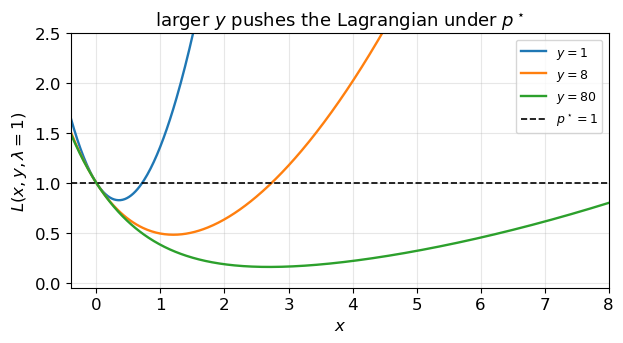

(CVXPY) Oct 11 10:54:37 AM: Your problem has 2 variables, 1 constraints, and 0 parameters.
(CVXPY) Oct 11 10:54:37 AM: It is compliant with the following grammars: DCP, DQCP
(CVXPY) Oct 11 10:54:37 AM: (If you need to solve this problem multiple times, but with different data, consider using parameters.)
(CVXPY) Oct 11 10:54:37 AM: CVXPY will first compile your problem; then, it will invoke a numerical solver to obtain a solution.
(CVXPY) Oct 11 10:54:37 AM: Your problem is compiled with the CPP canonicalization backend.
(CVXPY) Oct 11 10:54:37 AM: Compiling problem (target solver=SCS).
(CVXPY) Oct 11 10:54:37 AM: Reduction chain: Dcp2Cone -> CvxAttr2Constr -> ConeMatrixStuffing -> SCS
(CVXPY) Oct 11 10:54:37 AM: Applying reduction Dcp2Cone
(CVXPY) Oct 11 10:54:37 AM: Applying reduction CvxAttr2Constr
(CVXPY) Oct 11 10:54:37 AM: Applying reduction ConeMatrixStuffing
(CVXPY) Oct 11 10:54:37 AM: Applying reduction SCS
(CVXPY) Oct 11 10:54:37 AM: Finished problem compilation (took 5.921e-

                                     CVXPY                                     
                                     v1.7.5                                    
-------------------------------------------------------------------------------
                                  Compilation                                  
-------------------------------------------------------------------------------
-------------------------------------------------------------------------------
                                Numerical solver                               
-------------------------------------------------------------------------------
------------------------------------------------------------------
	       SCS v3.2.11 - Splitting Conic Solver
	(c) Brendan O'Donoghue, Stanford University, 2012
------------------------------------------------------------------
problem:  variables n: 4, constraints m: 7
cones: 	  l: linear vars: 1
	  q: soc vars: 3, qsize: 1
	  e: exp vars: 3, dual exp var

In [3]:
# Boyd's gap: every feasible objective equals 1, and the Lagrangian can be driven to 0.
def lagrangian(x, y, lam):
    return np.exp(-x) + lam * (x**2) / y

xs = np.linspace(-1.0, 30.0, 4000)
y_large = 1e6
print("on the feasible ray x=0, y>0, the objective equals", np.exp(0.0))
print(f"{'λ':>8}  {'best L at y=1e6':>18}")
for lam in (0.0, 1.0, 10.0):
    vals = lagrangian(xs, y_large, lam)
    print(f"{lam:8.1f}  {vals.min():18.3e}")
print("each row is an upper estimate of g(λ);  g is in fact 0, so d* = 0 < 1 = p*")

fig, ax = plt.subplots(figsize=(6.4, 3.6))
xs_plot = np.linspace(-0.4, 8.0, 500)
for y_val in (1.0, 8.0, 80.0):
    ax.plot(xs_plot, lagrangian(xs_plot, y_val, 1.0), lw=1.7, label=rf"$y={y_val:g}$")
ax.axhline(1.0, color="k", lw=1.2, ls="--", label=r"$p^\star=1$")
ax.set_xlim(-0.4, 8.0)
ax.set_ylim(-0.05, 2.5)
ax.set_xlabel("$x$")
ax.set_ylabel(r"$L(x, y, \lambda=1)$")
ax.legend(fontsize=9)
ax.set_title(r"larger $y$ pushes the Lagrangian under $p^\star$")
fig.tight_layout()
plt.show()


import cvxpy as cp

x = cp.Variable(2)
problem = cp.Problem(cp.Minimize(cp.exp(-x[0])), [cp.quad_over_lin(x[0], x[1]) <= 0])
problem.solve(solver=cp.SCS, verbose=True)
print(problem.status)
print(problem.constraints[0].dual_variables[0].value)


## Strong duality

Assume $f_0$ and each $f_i$ convex, and the equalities affine. 

- If Slater's condition holds, then

$$
p^\star=d^\star,
$$

and a dual optimal pair $(\boldsymbol{\lambda}^\star,\boldsymbol{\nu}^\star)$ exists. 
- If a primal minimizer $\mathbf{x}^\star$ exists as well, the triple $(\mathbf{x}^\star,\boldsymbol{\lambda}^\star,\boldsymbol{\nu}^\star)$ satisfies KKT.

- The number a solver reports as the duality gap is then a distance to optimality, up to the tolerance of the linear algebra. 
- A large gap on a convex model is a numerical failure, an infeasible model, or an unbounded one. 
- A large gap on a nonconvex model can be the geometry itself: the dual is still a bound.


## Where a solver keeps the multipliers

CVXPY stores an optimal dual variable on each constraint, as `constraint.dual_value`.

- A constraint written $f_i(\mathbf{x})\le 0$ stores $\lambda_i\ge 0$.
- A constraint written $\mathbf{A}\mathbf{x}-\mathbf{b}=\mathbf{0}$ stores $\boldsymbol{\nu}$.

The checks in the remaining cells are arithmetic on those numbers: a stationarity residual, the products $\lambda_i f_i(\mathbf{x})$, and the gap $f_0(\mathbf{x})-g(\boldsymbol{\lambda},\boldsymbol{\nu})$. Write the constraint in the template form and the sign of `dual_value` matches the Lagrangian on the previous slides.


## Shadow prices on a two-ingredient blend

$$
\begin{array}{ll}
\text{minimize}  & 2x+y \\
\text{subject to}& x+y\ge 2,\quad x\ge \tfrac12,\\
                 & y\ge 0,\quad x\le 3,\quad y\le 2.
\end{array}
$$

Write each inequality as $f_i\le 0$. The Lagrangian is linear in $(x,y)$, so $g(\boldsymbol{\lambda})$ is finite only when the coefficients of $x$ and of $y$ vanish. The dual is the linear program

$$
\begin{array}{ll}
\text{maximize}  & 2\lambda_1+\tfrac12\lambda_2-3\lambda_4-2\lambda_5 \\
\text{subject to}& 2-\lambda_1-\lambda_2+\lambda_4=0,\\
                 & 1-\lambda_1-\lambda_3+\lambda_5=0,\\
                 & \boldsymbol{\lambda}\ge\mathbf{0}.
\end{array}
$$

$\lambda_1$ prices demand and $\lambda_2$ prices the contract on $x$. Both problems attain $5/2$, at $(x,y)=(1/2,\,3/2)$ and $\boldsymbol{\lambda}=(1,1,0,0,0)$. Lowering demand from $2$ to $2-u$ lowers the optimal cost by $u$.


(CVXPY) Oct 09 07:05:18 PM: Your problem has 2 variables, 5 constraints, and 0 parameters.
(CVXPY) Oct 09 07:05:18 PM: It is compliant with the following grammars: DCP, DQCP
(CVXPY) Oct 09 07:05:18 PM: (If you need to solve this problem multiple times, but with different data, consider using parameters.)
(CVXPY) Oct 09 07:05:18 PM: CVXPY will first compile your problem; then, it will invoke a numerical solver to obtain a solution.
(CVXPY) Oct 09 07:05:18 PM: Your problem is compiled with the CPP canonicalization backend.
(CVXPY) Oct 09 07:05:18 PM: Compiling problem (target solver=CLARABEL).
(CVXPY) Oct 09 07:05:18 PM: Reduction chain: Dcp2Cone -> CvxAttr2Constr -> ConeMatrixStuffing -> CLARABEL
(CVXPY) Oct 09 07:05:18 PM: Applying reduction Dcp2Cone
(CVXPY) Oct 09 07:05:18 PM: Applying reduction CvxAttr2Constr
(CVXPY) Oct 09 07:05:18 PM: Applying reduction ConeMatrixStuffing
(CVXPY) Oct 09 07:05:18 PM: Applying reduction CLARABEL
(CVXPY) Oct 09 07:05:18 PM: Finished problem compilatio

                                     CVXPY                                     
                                     v1.7.5                                    
-------------------------------------------------------------------------------
                                  Compilation                                  
-------------------------------------------------------------------------------
-------------------------------------------------------------------------------
                                Numerical solver                               
-------------------------------------------------------------------------------
-------------------------------------------------------------
           Clarabel.rs v0.11.1  -  Clever Acronym                

                   (c) Paul Goulart                          
                University of Oxford, 2022                   
-------------------------------------------------------------

problem:
  variables     = 2
  constraints  

(CVXPY) Oct 09 07:05:18 PM: Problem status: optimal
(CVXPY) Oct 09 07:05:18 PM: Optimal value: 2.500e+00
(CVXPY) Oct 09 07:05:18 PM: Compilation took 5.429e-03 seconds
(CVXPY) Oct 09 07:05:18 PM: Solver (including time spent in interface) took 2.024e-03 seconds
(CVXPY) Oct 09 07:05:18 PM: Your problem has 2 variables, 5 constraints, and 0 parameters.
(CVXPY) Oct 09 07:05:18 PM: It is compliant with the following grammars: DCP, DQCP
(CVXPY) Oct 09 07:05:18 PM: (If you need to solve this problem multiple times, but with different data, consider using parameters.)
(CVXPY) Oct 09 07:05:18 PM: CVXPY will first compile your problem; then, it will invoke a numerical solver to obtain a solution.
(CVXPY) Oct 09 07:05:18 PM: Your problem is compiled with the CPP canonicalization backend.
(CVXPY) Oct 09 07:05:18 PM: Compiling problem (target solver=CLARABEL).
(CVXPY) Oct 09 07:05:18 PM: Reduction chain: Dcp2Cone -> CvxAttr2Constr -> ConeMatrixStuffing -> CLARABEL
(CVXPY) Oct 09 07:05:18 PM: Apply

  0  +3.9375e+00  -1.2500e-01  4.06e+00  1.66e-01  2.91e-01  1.00e+00  2.41e+00   ------   
  1  +3.1145e+00  +2.6106e+00  1.93e-01  2.55e-02  5.81e-02  1.52e-01  4.49e-01  8.45e-01  
  2  +2.5176e+00  +2.4472e+00  2.88e-02  3.42e-03  8.44e-03  2.37e-02  6.67e-02  8.75e-01  
  3  +2.5007e+00  +2.4994e+00  4.99e-04  6.15e-05  1.53e-04  4.32e-04  1.21e-03  9.83e-01  
  4  +2.5000e+00  +2.5000e+00  4.99e-06  6.15e-07  1.53e-06  4.32e-06  1.21e-05  9.90e-01  
  5  +2.5000e+00  +2.5000e+00  4.99e-08  6.15e-09  1.53e-08  4.32e-08  1.21e-07  9.90e-01  
  6  +2.5000e+00  +2.5000e+00  4.99e-10  6.15e-11  1.53e-10  4.32e-10  1.21e-09  9.90e-01  
---------------------------------------------------------------------------------------------
Terminated with status = Solved
solve time = 66.584µs
-------------------------------------------------------------------------------
                                    Summary                                    
------------------------------------------------

(CVXPY) Oct 09 07:05:18 PM: Problem status: optimal
(CVXPY) Oct 09 07:05:18 PM: Optimal value: 2.500e+00
(CVXPY) Oct 09 07:05:18 PM: Compilation took 4.655e-03 seconds
(CVXPY) Oct 09 07:05:18 PM: Solver (including time spent in interface) took 1.198e-03 seconds
(CVXPY) Oct 09 07:05:18 PM: Your problem has 2 variables, 5 constraints, and 0 parameters.
(CVXPY) Oct 09 07:05:18 PM: It is compliant with the following grammars: DCP, DQCP
(CVXPY) Oct 09 07:05:18 PM: (If you need to solve this problem multiple times, but with different data, consider using parameters.)
(CVXPY) Oct 09 07:05:18 PM: CVXPY will first compile your problem; then, it will invoke a numerical solver to obtain a solution.
(CVXPY) Oct 09 07:05:18 PM: Your problem is compiled with the CPP canonicalization backend.
(CVXPY) Oct 09 07:05:18 PM: Compiling problem (target solver=CLARABEL).
(CVXPY) Oct 09 07:05:18 PM: Reduction chain: Dcp2Cone -> CvxAttr2Constr -> ConeMatrixStuffing -> CLARABEL
(CVXPY) Oct 09 07:05:18 PM: Apply

  0  +3.9375e+00  -1.2500e-01  4.06e+00  1.66e-01  2.91e-01  1.00e+00  2.41e+00   ------   
  1  +3.1145e+00  +2.6106e+00  1.93e-01  2.55e-02  5.81e-02  1.52e-01  4.49e-01  8.45e-01  
  2  +2.5176e+00  +2.4472e+00  2.88e-02  3.42e-03  8.44e-03  2.37e-02  6.67e-02  8.75e-01  
  3  +2.5007e+00  +2.4994e+00  4.99e-04  6.15e-05  1.53e-04  4.32e-04  1.21e-03  9.83e-01  
  4  +2.5000e+00  +2.5000e+00  4.99e-06  6.15e-07  1.53e-06  4.32e-06  1.21e-05  9.90e-01  
  5  +2.5000e+00  +2.5000e+00  4.99e-08  6.15e-09  1.53e-08  4.32e-08  1.21e-07  9.90e-01  
  6  +2.5000e+00  +2.5000e+00  4.99e-10  6.15e-11  1.53e-10  4.32e-10  1.21e-09  9.90e-01  
---------------------------------------------------------------------------------------------
Terminated with status = Solved
solve time = 55.169µs
-------------------------------------------------------------------------------
                                    Summary                                    
------------------------------------------------

(CVXPY) Oct 09 07:05:18 PM: Problem status: optimal
(CVXPY) Oct 09 07:05:18 PM: Optimal value: 2.400e+00
(CVXPY) Oct 09 07:05:18 PM: Compilation took 3.511e-03 seconds
(CVXPY) Oct 09 07:05:18 PM: Solver (including time spent in interface) took 1.234e-03 seconds
(CVXPY) Oct 09 07:05:18 PM: Your problem has 2 variables, 5 constraints, and 0 parameters.
(CVXPY) Oct 09 07:05:18 PM: It is compliant with the following grammars: DCP, DQCP
(CVXPY) Oct 09 07:05:18 PM: (If you need to solve this problem multiple times, but with different data, consider using parameters.)
(CVXPY) Oct 09 07:05:18 PM: CVXPY will first compile your problem; then, it will invoke a numerical solver to obtain a solution.
(CVXPY) Oct 09 07:05:18 PM: Your problem is compiled with the CPP canonicalization backend.
(CVXPY) Oct 09 07:05:18 PM: Compiling problem (target solver=CLARABEL).
(CVXPY) Oct 09 07:05:18 PM: Reduction chain: Dcp2Cone -> CvxAttr2Constr -> ConeMatrixStuffing -> CLARABEL
(CVXPY) Oct 09 07:05:18 PM: Apply

  0  +3.8625e+00  -3.6250e-01  4.22e+00  1.55e-01  2.93e-01  1.00e+00  2.35e+00   ------   
  1  +3.0044e+00  +2.4690e+00  2.17e-01  2.38e-02  5.93e-02  1.46e-01  4.34e-01  8.43e-01  
  2  +2.4222e+00  +2.3500e+00  3.07e-02  3.10e-03  8.36e-03  2.21e-02  6.23e-02  8.78e-01  
  3  +2.4005e+00  +2.3994e+00  4.29e-04  4.47e-05  1.21e-04  3.18e-04  9.03e-04  9.86e-01  
  4  +2.4000e+00  +2.4000e+00  4.28e-06  4.47e-07  1.21e-06  3.18e-06  9.03e-06  9.90e-01  
  5  +2.4000e+00  +2.4000e+00  4.28e-08  4.47e-09  1.21e-08  3.18e-08  9.03e-08  9.90e-01  
  6  +2.4000e+00  +2.4000e+00  4.28e-10  4.47e-11  1.21e-10  3.18e-10  9.03e-10  9.90e-01  
---------------------------------------------------------------------------------------------
Terminated with status = Solved
solve time = 59.96µs
-------------------------------------------------------------------------------
                                    Summary                                    
-------------------------------------------------

(CVXPY) Oct 09 07:05:18 PM: Problem status: optimal
(CVXPY) Oct 09 07:05:18 PM: Optimal value: 2.300e+00
(CVXPY) Oct 09 07:05:18 PM: Compilation took 3.464e-03 seconds
(CVXPY) Oct 09 07:05:18 PM: Solver (including time spent in interface) took 1.390e-03 seconds


  0  +3.7875e+00  -6.0000e-01  4.39e+00  1.43e-01  2.94e-01  1.00e+00  2.29e+00   ------   
  1  +2.8968e+00  +2.3318e+00  2.42e-01  2.19e-02  6.03e-02  1.40e-01  4.17e-01  8.42e-01  
  2  +2.3261e+00  +2.2550e+00  3.16e-02  2.70e-03  7.99e-03  1.99e-02  5.61e-02  8.85e-01  
  3  +2.3003e+00  +2.2995e+00  3.72e-04  3.27e-05  9.71e-05  2.39e-04  6.83e-04  9.88e-01  
  4  +2.3000e+00  +2.3000e+00  3.72e-06  3.27e-07  9.71e-07  2.39e-06  6.83e-06  9.90e-01  
  5  +2.3000e+00  +2.3000e+00  3.72e-08  3.27e-09  9.71e-09  2.39e-08  6.83e-08  9.90e-01  
  6  +2.3000e+00  +2.3000e+00  3.72e-10  3.27e-11  9.71e-11  2.39e-10  6.83e-10  9.90e-01  
---------------------------------------------------------------------------------------------
Terminated with status = Solved
solve time = 41.043µs
-------------------------------------------------------------------------------
                                    Summary                                    
------------------------------------------------

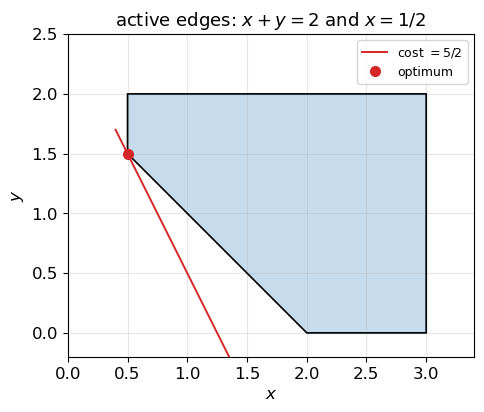

In [17]:
# Blend LP: multipliers, dual objective, and a finite-difference check of ∂p*/∂(demand).
names = ["demand  x+y >= d", "contract x >= 1/2", "y >= 0", "x <= 3", "y <= 2"]

def solve_blend(demand):
    v = cp.Variable(2)
    cons = [
        demand - v[0] - v[1] <= 0,
        0.5 - v[0] <= 0,
        -v[1] <= 0,
        v[0] - 3 <= 0,
        v[1] - 2 <= 0,
    ]
    problem = cp.Problem(cp.Minimize(2 * v[0] + v[1]), cons)
    problem.solve(solver=cp.CLARABEL, verbose=True)
    lam = np.array([float(np.asarray(c.dual_value).ravel()[0]) for c in cons])
    return v.value, float(problem.value), lam

x_hat, p_star, lam = solve_blend(2.0)
dual_obj = 2 * lam[0] + 0.5 * lam[1] - 3 * lam[3] - 2 * lam[4]
slacks = np.array(
    [
        2.0 - x_hat[0] - x_hat[1],
        0.5 - x_hat[0],
        -x_hat[1],
        x_hat[0] - 3,
        x_hat[1] - 2,
    ]
)
slacks = np.where(np.abs(slacks) < 1e-8, 0.0, slacks)
# Stationarity of 2x+y plus λ-weighted gradients of the five inequalities.
grad = np.array([2.0, 1.0]) + lam[0] * np.array([-1.0, -1.0])
grad = grad + lam[1] * np.array([-1.0, 0.0]) + lam[2] * np.array([0.0, -1.0])
grad = grad + lam[3] * np.array([1.0, 0.0]) + lam[4] * np.array([0.0, 1.0])

print(f"primal x = ({x_hat[0]:.3f}, {x_hat[1]:.3f})    p* = {p_star:.3f}    dual = {dual_obj:.3f}")
print(f"stationarity residual = {np.linalg.norm(grad):.2e}")
print(f"{'constraint':<20} {'λ':>8} {'f_i(x)':>10}   (written ≤ 0)")
for name, li, si in zip(names, lam, slacks):
    print(f"{name:<20} {li:8.3f} {si:10.3f}")
print()
print(f"{'demand':>8} {'p*':>8} {'p*(2)-λ1·u':>12}")
for u in (0.0, 0.1, 0.2):
    _, p_u, _ = solve_blend(2.0 - u)
    print(f"{2.0 - u:8.1f} {p_u:8.3f} {p_star - lam[0] * u:12.3f}")

verts = np.array([[0.5, 1.5], [0.5, 2.0], [3.0, 2.0], [3.0, 0.0], [2.0, 0.0]])
fig, ax = plt.subplots(figsize=(5.0, 4.2))
ax.fill(verts[:, 0], verts[:, 1], color="C0", alpha=0.25)
ax.plot(*np.vstack([verts, verts[:1]]).T, color="k", lw=1.2)
level_x = np.linspace(0.4, 1.4, 50)
ax.plot(level_x, 2.5 - 2 * level_x, color="C3", lw=1.4, label=r"cost $=5/2$")
ax.plot(*x_hat, "o", color="C3", ms=7, label="optimum")
ax.set_xlim(0, 3.4)
ax.set_ylim(-0.2, 2.5)
ax.set_xlabel("$x$")
ax.set_ylabel("$y$")
ax.set_aspect("equal")
ax.legend(fontsize=9, loc="upper right")
ax.set_title(r"active edges: $x+y=2$ and $x=1/2$")
fig.tight_layout()
plt.show()


### Projection onto a subspace

The Euclidean projection of the origin onto the affine set $\{\mathbf{x}:\mathbf{A}\mathbf{x}=\mathbf{b}\}$ is

$$
\begin{array}{ll}
\text{minimize}  & \tfrac{1}{2}\|\mathbf{x}\|_2^2 \\
\text{subject to}& \mathbf{A}\mathbf{x}=\mathbf{b}.
\end{array}
$$

$\mathbf{A}$ is $m\times n$ and $m < n$.

- Write down the Lagrangian:

$$
L(\mathbf{x},\boldsymbol{\nu})
=\tfrac12\|\mathbf{x}\|_2^2+\boldsymbol{\nu}^\top(\mathbf{A}\mathbf{x}-\mathbf{b})
=\tfrac12\|\mathbf{x}\|_2^2+\langle\mathbf{A}^\top\boldsymbol{\nu},\mathbf{x}\rangle-\mathbf{b}^\top\boldsymbol{\nu}.
$$

- Use definition of dual function

$$ g(\boldsymbol{\nu}) = \inf_{\mathbf{x}} L(\mathbf{x},\boldsymbol{\nu}) $$

- Since the above problem is unconstrained and the Lagrangian is convex function w.r.t. $\mathbf{x}$ (check!), we can use the first-order optimality conditions:

$$ L'_{\mathbf{x}}(\mathbf{x},\boldsymbol{\nu}) = \mathbf{x} + \mathbf{A}^\top \boldsymbol{\nu} = 0$$

- Therefore $\mathbf{x}^* = -\mathbf{A}^\top \boldsymbol{\nu}$ and the dual function is

$$
g(\boldsymbol{\nu})
=\inf_{\mathbf{x}} L(\mathbf{x},\boldsymbol{\nu}) = L(\mathbf{x}^*, \boldsymbol{\nu}) = 
=-\mathbf{b}^\top\boldsymbol{\nu}-\tfrac12\|\mathbf{A}^\top\boldsymbol{\nu}\|_2^2.
$$

Check that the derived dual frunction is concave that matched the theory discussed above.

- The dual problem is the unconstrained maximization of this concave quadratic

$$ \max  g(\boldsymbol{\nu}) $$


#### How to solve this dual probem and check strong duality

- Since it is essentially convex optimization problem (max of convex is equal to min of convex), we can again use the first order optimality condition to resolve it analytically!
-  Its gradient is $g'(\boldsymbol{\nu})=-\mathbf{b}-\mathbf{A}\mathbf{A}^\top\boldsymbol{\nu}$, so a critical point solves $\mathbf{A}\mathbf{A}^\top\boldsymbol{\nu}=-\mathbf{b}$. 
- When $\mathbf{A}$ has full row rank, $\mathbf{A}\mathbf{A}^\top$ is invertible and

$$
\boldsymbol{\nu}^\star=-(\mathbf{A}\mathbf{A}^\top)^{-1}\mathbf{b},
\qquad
\mathbf{x}^\star=-\mathbf{A}^\top\boldsymbol{\nu}^\star=\mathbf{A}^\top(\mathbf{A}\mathbf{A}^\top)^{-1}\mathbf{b}.
$$

- The second formula is the minimum-norm solution of $\mathbf{A}\mathbf{x}=\mathbf{b}$. Either expression gives the common optimal value

$$
p^\star=\tfrac12\|\mathbf{x}^\star\|_2^2=\tfrac12\mathbf{b}^\top(\mathbf{A}\mathbf{A}^\top)^{-1}\mathbf{b}=g(\boldsymbol{\nu}^\star)=d^\star.
$$

- Thus, we show that strong duality holds!


### Sparse recovery, and the dual certificate

Measure a vector with fewer rows than unknowns, and ask for the explanation with the smallest $\ell_1$ norm:

$$
\begin{array}{ll}
\text{minimize}  & \|\mathbf{x}\|_1 \\
\text{subject to}& \mathbf{A}\mathbf{x}=\mathbf{b}.
\end{array}
$$

$\mathbf{A}$ is $m\times n$ with $m<n$. This is basis pursuit. Compressed sensing uses it to reconstruct a sparse signal — an image, a spectrum — from fewer linear measurements than the ambient dimension.

- Write the constraint as $\mathbf{A}\mathbf{x}-\mathbf{b}=\mathbf{0}$ and the corresponding Lagrange multiplier is $\boldsymbol{\nu}\in\mathbb{R}^m$:

$$
L(\mathbf{x},\boldsymbol{\nu})=\|\mathbf{x}\|_1+\boldsymbol{\nu}^\top(\mathbf{A}\mathbf{x}-\mathbf{b}).
$$

- The infimum over $\mathbf{x}$ is finite exactly when $\|\mathbf{A}^\top\boldsymbol{\nu}\|_\infty\le 1$, and then $g(\boldsymbol{\nu})=-\mathbf{b}^\top\boldsymbol{\nu}$. The dual is

$$
\begin{array}{ll}
\text{maximize}  & -\mathbf{b}^\top\boldsymbol{\nu} \\
\text{subject to}& \|\mathbf{A}^\top\boldsymbol{\nu}\|_\infty\le 1.
\end{array}
$$

- Complementary slackness reads the support off the certificate $\mathbf{A}^\top\boldsymbol{\nu}$:

    - $|(\mathbf{A}^\top\boldsymbol{\nu})_i|<1$ forces $x_i=0$.
    - $x_i\neq 0$ forces $(\mathbf{A}^\top\boldsymbol{\nu})_i=-\mathrm{sign}(x_i)$.

A dual-feasible $\boldsymbol{\nu}$ that saturates exactly on a set $S$, together with a feasible $\mathbf{x}$ supported on $S$ with those signs, certifies optimality. The multiplier is a proof that no other explanation of $\mathbf{b}$ has a smaller $\ell_1$ norm.


p* = 2.400000    dual = 2.400000
||x - x_true|| = 1.30e-09
||A^T ν||_∞    = 1.000000
A^T ν on the support = [-1.  1. -1.]    -sign(x) = [-1.  1. -1.]
max |A^T ν| off the support = 0.869


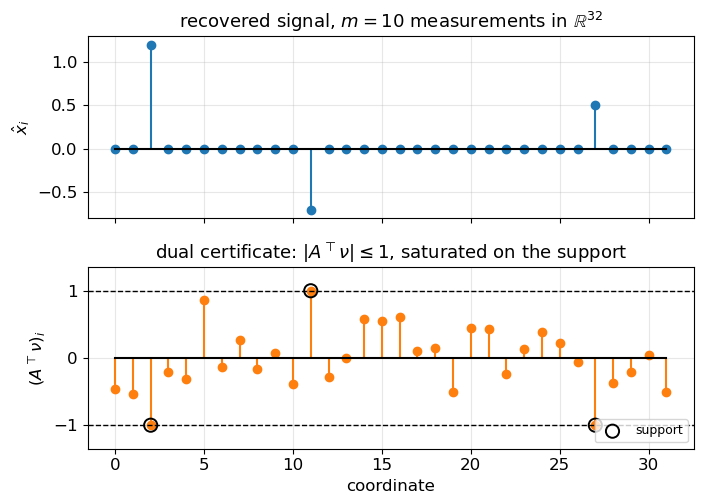

In [19]:
# Basis pursuit: a 3-sparse vector in R^32, from 10 linear measurements.
rng = np.random.default_rng(0)
n, m = 32, 10
A = rng.normal(size=(m, n))
A /= np.linalg.norm(A, axis=0, keepdims=True)
support = np.array([2, 11, 27])
x_true = np.zeros(n)
x_true[support] = np.array([1.2, -0.7, 0.5])
b = A @ x_true

x = cp.Variable(n)
equality = A @ x - b == 0
problem = cp.Problem(cp.Minimize(cp.norm1(x)), [equality])
problem.solve(solver=cp.CLARABEL)

nu = np.asarray(equality.dual_value).ravel()
certificate = A.T @ nu
dual_obj = float(-b @ nu)
x_hat = np.asarray(x.value).ravel()

print(f"p* = {problem.value:.6f}    dual = {dual_obj:.6f}")
print(f"||x - x_true|| = {np.linalg.norm(x_hat - x_true):.2e}")
print(f"||A^T ν||_∞    = {np.max(np.abs(certificate)):.6f}")
print(f"A^T ν on the support = {np.round(certificate[support], 6)}    -sign(x) = {-np.sign(x_true[support])}")
off_support = np.abs(x_hat) <= 1e-6
print(f"max |A^T ν| off the support = {np.max(np.abs(certificate[off_support])):.3f}")

fig, axes = plt.subplots(2, 1, figsize=(7.2, 5.2), sharex=True)
idx = np.arange(n)
axes[0].stem(idx, x_hat, linefmt="C0-", markerfmt="C0o", basefmt="k-")
axes[0].set_ylabel(r"$\hat{x}_i$")
axes[0].set_title(r"recovered signal, $m=10$ measurements in $\mathbb{R}^{32}$")
axes[1].stem(idx, certificate, linefmt="C1-", markerfmt="C1o", basefmt="k-")
axes[1].axhline(1.0, color="k", lw=1.0, ls="--")
axes[1].axhline(-1.0, color="k", lw=1.0, ls="--")
axes[1].scatter(
    support,
    certificate[support],
    s=90,
    facecolors="none",
    edgecolors="k",
    linewidths=1.4,
    zorder=4,
    label="support",
)
axes[1].set_xlabel("coordinate")
axes[1].set_ylabel(r"$(A^\top\nu)_i$")
axes[1].set_ylim(-1.35, 1.35)
axes[1].legend(fontsize=9, loc="lower right")
axes[1].set_title(r"dual certificate: $|A^\top\nu|\leq 1$, saturated on the support")
fig.tight_layout()
plt.show()


## Conic duality

- Previously we have discussed the process of derivation dual program for both differentiable and non-differentiable primal problems.
- The natural question is how unify the process of such deribations?
- The answer comes from the conic problems formalism.

Consider the convex optimization problem in conic form: 

$$
\begin{array}{ll}
\text{minimize}  & \mathbf{c}^\top\mathbf{x} \\
\text{subject to}& \mathbf{A}\mathbf{x}=\mathbf{b}, \\
                 & \mathbf{x}\in K.
\end{array}
$$
- An LP takes $K$ to be the nonnegative orthant. 
- An SOCP or an SDP is a product of a second-order cone, or a PSD cone, with an orthant. 
- The blend on the previous slides is this template with $K=\mathbb{R}_+^n$ after slacks are introduced.

To construct the dual problem to the conic problem, we introduce the **dual cone**.




### Dual cone

Given a cone $K$, then the dual cone is 
$$
K^\star=\{\mathbf{s}:\langle\mathbf{s},\mathbf{x}\rangle\ge 0\text{ for every }\mathbf{x}\in K\}.
$$

The figure dualizes one cone in $\mathbb{R}^2$ by hand. $K$ is the set of nonnegative combinations of $(1,0)$ and $(1,2)$. A vector lies in $K^\star$ when its inner product with both generators is nonnegative, so $K^\star$ is the set of nonnegative combinations of the perpendiculars $(0,1)$ and $(2,-1)$. Dashed rays are the extreme rays of the other cone, and each right angle marks an orthogonal pair. The two opening angles add to $\pi$.


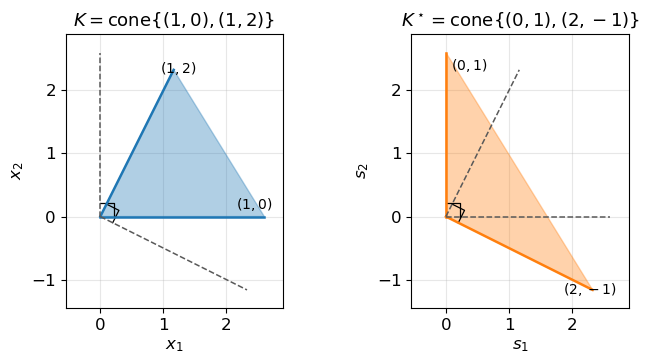

In [5]:
# Dual of the polyhedral cone generated by (1, 0) and (1, 2).
# s is in K* exactly when it pairs nonnegatively with both generators,
# so the extreme rays of K* are the perpendiculars (0, 1) and (2, -1).

def _unit(vector):
    vector = np.asarray(vector, dtype=float)
    return vector / np.linalg.norm(vector)


def _fill_cone(ax, ray_a, ray_b, length, **kwargs):
    tips = length * np.vstack([_unit(ray_a), _unit(ray_b)])
    polygon = np.vstack([[0.0, 0.0], tips])
    ax.fill(polygon[:, 0], polygon[:, 1], **kwargs)
    return tips


def _right_angle(ax, ray_u, ray_v, size=0.22):
    u, v = _unit(ray_u), _unit(ray_v)
    corner = size * np.vstack([u, u + v, v])
    ax.plot(corner[:, 0], corner[:, 1], color="k", lw=0.9)


primal_rays = ((1.0, 0.0), (1.0, 2.0))
dual_rays = ((0.0, 1.0), (2.0, -1.0))
length = 2.6

fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.8))
panels = (
    (axes[0], primal_rays, "C0", r"$K=\mathrm{cone}\{(1,0),(1,2)\}$", "$x_1$", "$x_2$"),
    (axes[1], dual_rays, "C1", r"$K^\star=\mathrm{cone}\{(0,1),(2,-1)\}$", "$s_1$", "$s_2$"),
)
for ax, own, color, title, xlabel, ylabel in panels:
    _fill_cone(ax, own[0], own[1], length, color=color, alpha=0.35, zorder=2)
    for ray in own:
        tip = length * _unit(ray)
        ax.plot([0.0, tip[0]], [0.0, tip[1]], color=color, lw=1.8, zorder=3)
    other = dual_rays if own is primal_rays else primal_rays
    for ray in other:
        tip = length * _unit(ray)
        ax.plot([0.0, tip[0]], [0.0, tip[1]], color="0.35", lw=1.1, ls="--", zorder=3)
    _right_angle(ax, primal_rays[0], dual_rays[0])
    _right_angle(ax, primal_rays[1], dual_rays[1])
    ax.set_aspect("equal")
    ax.set_xlim(-0.55, 2.9)
    ax.set_ylim(-1.45, 2.9)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title)

axes[0].annotate(r"$(1,0)$", (2.15, 0.12), fontsize=10)
axes[0].annotate(r"$(1,2)$", (0.95, 2.28), fontsize=10)
axes[1].annotate(r"$(0,1)$", (0.08, 2.32), fontsize=10)
axes[1].annotate(r"$(2,-1)$", (1.85, -1.22), fontsize=10)
fig.tight_layout()
plt.show()



### Standard cones and their duals

| cone | set | dual cone |
|---|---|---|
| nonnegative orthant | $\mathbf{x}\ge\mathbf{0}$ | itself |
| zero cone | $\{\mathbf{0}\}$ | $\mathbb{R}^n$ |
| free space | $\mathbb{R}^n$ | $\{\mathbf{0}\}$ |
| second-order | $\Vert \mathbf{x}\Vert_2\le t$ | itself |
| PSD | $\mathbf{X}\succeq 0$ | itself |
| exponential | $\mathrm{cl}\{(x,y,t): y>0,\ ye^{x/y}\le t\}$ | $\mathrm{cl}\{(u,v,w): u<0,\ -ue^{v/u}\le ew\}$ |
| power, $0<\alpha<1$ | $x_1^\alpha x_2^{1-\alpha}\ge\lvert x_3\rvert$, $x_1,x_2\ge 0$ | $(y_1/\alpha,\ y_2/(1-\alpha),\ y_3)$ in the same cone |
| $p$-norm, $1\le p\le\infty$ | $\Vert \mathbf{x}\Vert_p\le t$ | the $q$-norm cone, $1/p+1/q=1$ |

- The orthant is self-dual because $\mathbf{s}^\top\mathbf{x}\ge 0$ for every $\mathbf{x}\ge\mathbf{0}$ holds exactly when every coordinate of $\mathbf{s}$ is nonnegative. Each standard basis vector forces one coordinate, and a nonnegative $\mathbf{s}$ keeps every such product nonnegative.

- The PSD cone is self-dual in the trace product. If $\mathbf{S}$ has a negative eigenvalue with a unit eigenvector $\mathbf{v}$, then $\mathbf{X}=\mathbf{v}\mathbf{v}^\top\succeq 0$ and $\langle\mathbf{S},\mathbf{X}\rangle=\mathbf{v}^\top\mathbf{S}\mathbf{v}<0$. If both matrices are positive semidefinite and $\mathbf{X}=\mathbf{F}\mathbf{F}^\top$, then $\langle\mathbf{S},\mathbf{X}\rangle=\mathrm{tr}(\mathbf{F}^\top\mathbf{S}\mathbf{F})\ge 0$.

- The zero cone is dual to the whole space: every vector pairs nonnegatively with $\mathbf{0}$, and a vector that pairs nonnegatively with every point of $\mathbb{R}^n$ is $\mathbf{0}$. 
- The second-order row is the case $p=2$ of the next derivation.

The [MOSEK Modeling Cookbook](https://docs.mosek.com/modeling-cookbook/index.html) is the guide for this catalogue: modeling with each cone in Ch. 2–6, and the dual of each cone in Ch. 8.


## Dual of a $p$-norm cone

- For $1\le p\le\infty$ the cone induced by $\|\cdot\|_p$ is

$$
K_p=\{(\mathbf{x},t)\in\mathbb{R}^n\times\mathbb{R}:\|\mathbf{x}\|_p\le t\}.
$$

- A pair $(\mathbf{y},s)$ lies in the dual when

$$
\mathbf{y}^\top\mathbf{x}+st\ge 0\qquad\text{for every }(\mathbf{x},t)\in K_p.
$$

- The scalar $s$ is nonnegative. If $s<0$, the points $(\mathbf{0},t)$ lie in $K_p$ for every $t\ge 0$, and $st\to-\infty$ as $t\to+\infty$.

- The inequality is homogeneous, so it is enough to test it on $t>0$ and on $(\mathbf{0},0)$. The origin contributes $0\ge 0$. For $t>0$ every feasible $\mathbf{x}$ is $t\mathbf{z}$ with $\|\mathbf{z}\|_p\le 1$, and

$$
\mathbf{y}^\top\mathbf{x}+st=t(\mathbf{y}^\top\mathbf{z}+s).
$$

- This is nonnegative for every such $\mathbf{z}$ exactly when

$$
s\ge\sup_{\|\mathbf{z}\|_p\le 1}(-\mathbf{y}^\top\mathbf{z})=\|\mathbf{y}\|_q,
$$

where $1/p+1/q=1$. The right-hand side is the dual norm from lecture 1. Hölder's inequality supplies the matching upper bound, $|\mathbf{y}^\top\mathbf{z}|\le\|\mathbf{y}\|_q\|\mathbf{z}\|_p\le\|\mathbf{y}\|_q$, and the bound is attained.

So $s\ge\|\mathbf{y}\|_q$ is necessary. It is also sufficient. 

- If $\|\mathbf{y}\|_q\le s$ and $\|\mathbf{x}\|_p\le t$, Hölder gives

$$
\mathbf{y}^\top\mathbf{x}+st\ge -\|\mathbf{y}\|_q\|\mathbf{x}\|_p+st\ge(s-\|\mathbf{y}\|_q)\,t\ge 0.
$$

- Therefore

$$
K_p^\star=K_q=\{(\mathbf{y},s):\|\mathbf{y}\|_q\le s\}.
$$

The Euclidean case $p=q=2$ is the second-order cone, which is dual to itself. The cones for $p=1$ and $p=\infty$ are dual to each other. The constraint $\|\mathbf{A}^\top\boldsymbol{\nu}\|_*\le 1$ in the vector-norm dual is the slice $s=1$ of this dual cone.


## The conic dual

Consider the conic problem

$$
\begin{array}{ll}
\text{minimize}  & \mathbf{c}^\top\mathbf{x} \\
\text{subject to}& \mathbf{A}\mathbf{x}=\mathbf{b}, \\
                 & \mathbf{x}\in K.
\end{array}
$$


- Construct the Lagrangian

$$
L(\mathbf{x},\boldsymbol{\nu})=\mathbf{c}^\top\mathbf{x}+\boldsymbol{\nu}^\top(\mathbf{A}\mathbf{x}-\mathbf{b}).
$$

- The infimum over $\mathbf{x}\in K$ equals $-\mathbf{b}^\top\boldsymbol{\nu}$ when $\mathbf{c}+\mathbf{A}^\top\boldsymbol{\nu}\in K^\star$, and $-\infty$ otherwise.

- A linear function on a cone is bounded below only when its slope lies in the dual cone, and the bound is then $0$ because $\mathbf{0}\in K$. 

- The dual problem is

$$
\begin{array}{ll}
\text{maximize}  & -\mathbf{b}^\top\boldsymbol{\nu} \\
\text{subject to}& \mathbf{c}+\mathbf{A}^\top\boldsymbol{\nu}\in K^\star.
\end{array}
$$


In [21]:
# min 1^T x subject to ||x||_2 <= 1, written as z = (x, t) in the second-order cone with t = 1.
n = 3
c = np.concatenate([np.ones(n), [0.0]])
e_last = np.zeros(n + 1)
e_last[-1] = 1.0

z = cp.Variable(n + 1)
equality = z[-1] == 1
cone = cp.SOC(z[-1], z[:n])
primal = cp.Problem(cp.Minimize(c @ z), [equality, cone])
primal.solve(solver=cp.CLARABEL)

nu = cp.Variable()
s = c + nu * e_last
dual = cp.Problem(cp.Maximize(-nu), [cp.SOC(s[-1], s[:n])])
dual.solve(solver=cp.CLARABEL)

s_hat = np.asarray(s.value).ravel()
z_hat = np.asarray(z.value).ravel()
# CVXPY stores the SOC dual as (t-multiplier, x-multiplier). Reorder it to (x, t).
s_from_solver = np.concatenate(
    [np.asarray(cone.dual_value[1]).ravel(), np.asarray(cone.dual_value[0]).ravel()]
)
print(f"p* = {primal.value:.6f}    dual = {dual.value:.6f}    -sqrt(n) = {-np.sqrt(n):.6f}")
print(f"equality dual_value = {float(equality.dual_value):.6f}    ν = {float(nu.value):.6f}")
print(f"gap <s, z> = {s_hat @ z_hat:.2e}")
print(f"||s - SOC.dual_value|| = {np.linalg.norm(s_hat - s_from_solver):.2e}")


p* = -1.732051    dual = -1.732051    -sqrt(n) = -1.732051
equality dual_value = 1.732051    ν = 1.732051
gap <s, z> = -6.85e-10
||s - SOC.dual_value|| = 5.40e-09


## The standard problem in conic form

Start from the template of lecture 1, with each $f_i$ convex:

$$
\begin{array}{ll}
\text{minimize}  & f_0(\mathbf{x}) \\
\text{subject to}& f_i(\mathbf{x})\le 0,\quad i=1,\ldots,m, \\
                 & \mathbf{A}\mathbf{x}=\mathbf{b}.
\end{array}
$$

Five steps turn it into 

$$
\begin{array}{ll}
\text{minimize}  & \mathbf{c}^\top\mathbf{z} \\
\text{subject to}& \mathbf{G}\mathbf{z}=\mathbf{h} \\
                 & \mathbf{z}\in K.
\end{array}
$$


1. **Epigraph the objective.** A new scalar $t$ carries the cost:

$$
\begin{array}{ll}
\text{minimize}  & t \\
\text{subject to}& f_0(\mathbf{x})\le t, \\
                 & f_i(\mathbf{x})\le 0, \\
                 & \mathbf{A}\mathbf{x}=\mathbf{b}.
\end{array}
$$

The optimal $\mathbf{x}$ is unchanged, and $p^\star$ equals the optimal $t$.

2. **One epigraph coordinate per inequality.** For each $i\ge 1$ introduce $t_i$ and write $f_i(\mathbf{x})\le t_i$ together with $t_i\le 0$. Every nonlinear piece now has the shape in the table, a convex function bounded by a scalar. The objective inequality is already $f_0(\mathbf{x})\le t$.

3. **Replace each convex inequality constraint with cone constraint.** The operations that build $K$ from $f$ are discussed in the next cell. 

4. **Add a slack for every cone membership.** A membership $\mathbf{F}_j\mathbf{z}-\mathbf{g}_j\in K_j$ becomes a new variable $\mathbf{s}_j\in K_j$ and an equality $\mathbf{F}_j\mathbf{z}-\mathbf{s}_j=\mathbf{g}_j$. Stack $\mathbf{x}$, the epigraph coordinates, the auxiliaries, and the slacks into one vector $\mathbf{z}$. That vector lies in a product of a free cone with the cones $K_j$.

5. **Read off the data.** The objective reads the coordinate $t$, so $\mathbf{c}$ is the corresponding standard basis vector. A feasible $\mathbf{z}$ has an $\mathbf{x}$-block feasible for the original problem and $t\ge f_0(\mathbf{x})$, so minimizing $t$ reproduces $p^\star$.

## Building $K$ from $f$

1. **A primitive epigraph is already a cone.** $\|\mathbf{x}\|_2\le t$ is $(\mathbf{x},t)$ in the second-order cone, so $K$ is that cone and the map is the identity. A linear matrix inequality is membership in the PSD cone.

2. **Affine precomposition keeps $K$.** If $f(\mathbf{x})\le t$ is an affine image of $(\mathbf{x},t)$ lying in $K$, then $f(\mathbf{C}\mathbf{x}+\mathbf{d})\le t$ is the same cone with $\mathbf{x}$ replaced by $\mathbf{C}\mathbf{x}+\mathbf{d}$. 

3. **An arbitrary closed convex function**. 

- A proper closed convex $f:\mathbb{R}^n\to\mathbb{R}\cup\{+\infty\}$ determines a cone.

- The epigraph $\{(\mathbf{x},t):f(\mathbf{x})\le t\}$ is a closed convex set. It is a cone when $f$ is positively homogeneous. In general, homogenize it:

$$
K_f=\mathrm{cl}\bigl\{(\mathbf{x},t,\lambda):\lambda>0,\ \lambda\,f(\mathbf{x}/\lambda)\le t\bigr\}.
$$

- $K_f$ is a closed convex cone in $\mathbb{R}^n\times\mathbb{R}\times\mathbb{R}_{+}$. The inequality is the slice $\lambda=1$:

$$
f(\mathbf{x})\le t \iff (\mathbf{x},t,1)\in K_f.
$$

- If $f(\mathbf{x})\le t$, the triple $(\mathbf{x},t,1)$ lies in the set before the closure. 
- Conversely, a point of the closure at height $1$ is a limit of $\lambda_k(\mathbf{x}_k,t_k,1)$ with $\lambda_k>0$ and $f(\mathbf{x}_k)\le t_k$. 
- Then $\lambda_k\to 1$, so $(\mathbf{x}_k,t_k)\to(\mathbf{x},t)$, and a closed epigraph contains the limit. 

The primitives are this same cone, equal to a standard one.

- $f(x)=e^{x}$ gives $\lambda\,e^{x/\lambda}\le t$, which is $(x,\lambda,t)$ in the exponential cone.
- $f(x)=x^2$ gives $x^2\le\lambda t$ with $\lambda>0$, a rotated second-order cone. That is the perspective of the square from the previous slide.
- A norm is positively homogeneous, so its epigraph is already a cone and the coordinate $\lambda$ is unnecessary.

When the four operations reduce $K_f$ to a product of 
- orthants
- second-order cones
- exponential cones, 
- PSD cones
- power cones

a solver checks membership in polynomial time. 

The copositive cone later in the lecture is a closed convex cone for which that reduction is unavailable.

In [8]:
# x^2/y <= t  and  ||(2x, y - t)||_2 <= y + t  describe the same pairs.
def cone_residual(x, y, t):
    return np.linalg.norm([2 * x, y - t]) - (y + t)

print(f"{'x':>4} {'y':>4} {'t':>4}  {'x^2/y - t':>10}  {'cone residual':>14}")
for x_val, y_val, t_val in [(2.0, 0.5, 8.0), (2.0, 0.5, 7.0), (2.0, 0.5, 9.0)]:
    gap = x_val**2 / y_val - t_val
    print(f"{x_val:4.1f} {y_val:4.1f} {t_val:4.1f}  {gap:10.1f}  {cone_residual(x_val, y_val, t_val):14.3f}")

x = cp.Variable()
y = cp.Variable(pos=True)
t = cp.Variable()
by_atom = cp.Problem(cp.Minimize(t), [cp.quad_over_lin(x, y) <= t, x == 2, y == 0.5])
by_atom.solve(solver=cp.CLARABEL)

x2 = cp.Variable()
y2 = cp.Variable()
t2 = cp.Variable()
by_cone = cp.Problem(
    cp.Minimize(t2),
    [cp.SOC(y2 + t2, cp.hstack([2 * x2, y2 - t2])), x2 == 2, y2 == 0.5],
)
by_cone.solve(solver=cp.CLARABEL)
print(f"atom t* = {by_atom.value:.6f}    second-order cone t* = {by_cone.value:.6f}")
print("a positive residual is a violation of that description")


   x    y    t   x^2/y - t   cone residual
 2.0  0.5  8.0         0.0           0.000
 2.0  0.5  7.0         1.0           0.132
 2.0  0.5  9.0        -1.0          -0.106
atom t* = 8.000000    second-order cone t* = 8.000000
a positive residual is a violation of that description


## The parser is building this encoding

- Lecture 2 called DCP a grammar, and said a parsed expression can be turned into a cone program.

- Each atom ships with a **graph implementation**: the cone representation of its epigraph, with the atom's arguments sitting in the affine map. CVXPY walks the expression tree from the leaves.

- A variable stays a coordinate of the cone program.
- At a node that passed the curvature rules, the parser allocates a new coordinate for the value of that node and emits the atom's cone constraints.
- An objective $f_0$ becomes "minimize $t$" plus the epigraph representation of $f_0$. The cone program has a linear objective. In the data a solver receives, $\mathbf{c}$ is a single $1$ in the epigraph coordinate and zeros elsewhere.
- A constraint $f_i\le 0$ forces the epigraph coordinate of $f_i$ into $-\mathbb{R}_+$.


In [9]:
def report(label, problem):
    data, _, _ = problem.get_problem_data(cp.CLARABEL)
    dims = data["dims"]
    c = np.asarray(data["c"]).ravel()
    print(
        f"{label:<44}  eq {dims.zero:<2}  orthant {dims.nonneg:<2}  "
        f"exp {dims.exp:<2}  SOC {list(dims.soc)}  linear objective nnz {int(np.count_nonzero(c))}"
    )

x = cp.Variable(2)
report("minimize ||x||_2", cp.Problem(cp.Minimize(cp.norm(x, 2))))

x = cp.Variable()
y = cp.Variable()
t = cp.Variable()
report(
    "minimize t  s.t. x^2/y <= t",
    cp.Problem(cp.Minimize(t), [cp.quad_over_lin(x, y) <= t]),
)

x = cp.Variable(3)
report("minimize log_sum_exp(x)", cp.Problem(cp.Minimize(cp.log_sum_exp(x))))

spelled = cp.log(cp.sum(cp.exp(x)))
atom = cp.log_sum_exp(x)
print(f"log(sum(exp(x)))   curvature {spelled.curvature:<12}  DCP {spelled.is_dcp()}")
print(f"log_sum_exp(x)     curvature {atom.curvature:<12}  DCP {atom.is_dcp()}")


minimize ||x||_2                              eq 0   orthant 0   exp 0   SOC [3]  linear objective nnz 1
minimize t  s.t. x^2/y <= t                   eq 0   orthant 1   exp 0   SOC [3]  linear objective nnz 1
minimize log_sum_exp(x)                       eq 0   orthant 1   exp 3   SOC []  linear objective nnz 1
log(sum(exp(x)))   curvature QUASICONVEX   DCP False
log_sum_exp(x)     curvature CONVEX        DCP True


## Barriers and polynomial complexity

- An interior-point method follows a path in the interior of $K$. We will discuss these methods later in the course.
- The path minimizes $\mathbf{c}^\top\mathbf{x}+\mu F(\mathbf{x})$ on the affine slice, and $\mu\downarrow 0$ pushes the point toward the boundary. 
- The function $F$ is a **barrier**: convex and smooth on the interior, with $F(\mathbf{x})\to+\infty$ as $\mathbf{x}$ approaches the boundary of $K$.

### Key property
**Self-concordance** bounds the third derivative by the second. For every interior point $\mathbf{x}$ and every direction $\mathbf{h}$,

$$
\bigl|D^3 F(\mathbf{x})[\mathbf{h},\mathbf{h},\mathbf{h}]\bigr|\le 2\bigl(D^2 F(\mathbf{x})[\mathbf{h},\mathbf{h}]\bigr)^{3/2}.
$$

- The brackets are directional derivatives along the line $\mathbf{x}+t\mathbf{h}$. With $\varphi(t)=F(\mathbf{x}+t\mathbf{h})$,

$$
D^2 F(\mathbf{x})[\mathbf{h},\mathbf{h}]=\varphi''(0)=\langle F''(\mathbf{x})\mathbf{h},\mathbf{h}\rangle,
\qquad
D^3 F(\mathbf{x})[\mathbf{h},\mathbf{h},\mathbf{h}]=\varphi'''(0),
$$

so the inequality says $|\varphi'''(0)|\le 2\,\varphi''(0)^{3/2}$. 
- Both sides are homogeneous of degree $3$ in $\mathbf{h}$: replacing $\mathbf{h}$ by $\alpha\mathbf{h}$ multiplies the third derivative by $\alpha^3$ and the second derivative by $\alpha^2$, and $(\alpha^2)^{3/2}=\alpha^3$. 
- An affine change of coordinates therefore preserves the inequality. 
- The constant $2$ is sharp for the barrier of a single ray. 

**Example**

- For $\varphi(t)=-\log t$ one has $\varphi''(t)=t^{-2}$ and $\varphi'''(t)=-2t^{-3}$, and the two sides are equal. 
- Inside the ellipsoid $\varphi''(0)<1$ the Hessian cannot change by more than a fixed factor, so the Newton step, measured in the local norm $\sqrt{\varphi''(0)}$, lands where the quadratic model is still valid.


### Examples of cones and correspinding barriers

| cone | barrier |
|---|---|
| nonnegative orthant $\mathbb{R}_+^n$ | $-\sum_i\log x_i$ |
| second-order, $\Vert \mathbf{x}\Vert_2\le t$ | $-\log(t^2-\Vert\mathbf{x}\Vert_2^2)$ |
| PSD, $\mathbf{X}\succ 0$ | $-\log\det\mathbf{X}$ |
| exponential, $t>ye^{x/y}$, $y>0$ | $-\log\bigl(y\log(t/y)-x\bigr)-\log y-\log t$ |
| power, $x_1^{\alpha}x_2^{1-\alpha}\ge\lvert x_3\rvert$ | $-\log\bigl(x_1^{2\alpha}x_2^{2(1-\alpha)}-x_3^2\bigr)-(1-\alpha)\log x_1-\alpha\log x_2$ |
| generalized power, $\prod_{i=1}^n x_i^{\alpha_i}\ge\lVert\mathbf{z}\rVert_2$ | $-\log\bigl(\prod_i x_i^{2\alpha_i}-\lVert\mathbf{z}\rVert_2^2\bigr)-\sum_i(1-\alpha_i)\log x_i$ |

A product of cones takes the sum of the barriers.

**Does every convex cone have such a barrier?**

- Yes! 
- Nesterov and Nemirovski constructed, for every closed convex cone with nonempty interior in $\mathbb{R}^n$, a logarithmically homogeneous self-concordant barrier. 
- At an interior point $\mathbf{x}$ the universal barrier is a constant times the logarithm of the volume of the polar set $\{\mathbf{s}:\langle\mathbf{s},\mathbf{y}-\mathbf{x}\rangle\le 1\text{ for every }\mathbf{y}\in K\}$.

**BUT!**

- Existence is not a polynomial algorithm. 
- The volume in that formula is not a polynomial-time oracle, and the complexity bound uses the value, the gradient, and the Hessian. 
- The copositive cone has the universal barrier. A polynomial-time Hessian for it would solve an NP-hard problem in polynomial time.


## Convex, and still NP-hard

- The encodings above are fast because each of those cones has a barrier whose Hessian is cheap. 
- The copositive cone is closed and convex, and the barrier it inherits from the general existence theorem is not a polynomial-time oracle!

The **copositive cone**

$$
\mathcal{COP}^n=\{\mathbf{M}\in\mathbf{S}^n: \mathbf{x}^\top\mathbf{M}\mathbf{x}\ge 0\text{ for every }\mathbf{x}\ge \mathbf{0}\}
$$

is an intersection of halfspaces, one for each $\mathbf{x}\ge \mathbf{0}$, so it is closed and convex. It contains the PSD cone. The containment is strict. The Horn matrix

$$
\mathbf{H}=\begin{pmatrix}
1&-1&1&1&-1\\
-1&1&-1&1&1\\
1&-1&1&-1&1\\
1&1&-1&1&-1\\
-1&1&1&-1&1
\end{pmatrix}
$$

has a negative eigenvalue, so it lies outside $\mathbf{S}_+^5$. On $\mathbf{x}\ge \mathbf{0}$ the form $\mathbf{x}^\top\mathbf{H}\mathbf{x}$ stays nonnegative, so $\mathbf{H}$ lies in $\mathcal{COP}^5$, on the boundary: the vector $(1,1,0,0,0)$ gives the value $0$.

Testing membership in $\mathcal{COP}^n$ is co-NP-complete, and linear optimization over the cone is NP-hard (Murty and Kabadi, 1987).


## The stability number is a convex program

For a graph $G$ on $n$ vertices with adjacency matrix $\mathbf{A}$, and $\mathbf{J}$ the all-ones matrix,

$$
\alpha(G)=\min\left\{t: t(\mathbf{I}+\mathbf{A})-\mathbf{J}\in\mathcal{COP}^n\right\}.
$$

- One variable, one convex constraint. 
- The optimal value is the size of a largest independent set (de Klerk and Pasechnik, 2002), which is NP-hard to compute.


## Takeaway

1. The Lagrangian prices the constraints. Its infimum over $\mathbf{x}$ is a concave function $g(\boldsymbol{\lambda},\boldsymbol{\nu})$, whether or not the primal is convex.
2. Every dual-feasible pair is a lower bound: $p^\star\ge d^\star$. The gap of a feasible pair is the length of an interval that contains $p^\star$, so a small gap certifies that both points are nearly optimal.
3. For a convex problem, Slater's condition makes the bound tight and produces KKT multipliers.
4. A cone program prices $\mathbf{A}\mathbf{x}=\mathbf{b}$ the same way. The dual constraint is membership in the dual cone, and weak duality is that cone's inequality. The orthant, the second-order cone, and the PSD cone equal their duals. The cone $\|\mathbf{x}\|_p\le t$ is dual to the cone $\|\mathbf{y}\|_q\le s$.
5. A convex inequality enters a cone program when its epigraph is a linear image of a standard cone. For an arbitrary closed convex $f$, the cone is the homogenization of the epigraph, and $f(\mathbf{x})\le t$ is the slice at height one. 
6. The standard problem becomes a cone program by one epigraph coordinate per atom, a slack for each cone membership, and a product cone. DCP walks the expression tree and stacks those representations. The program a solver receives has a linear objective.
7. The copositive formulation of the stability number is convex, and it is NP-hard.


### References — duality

- **Book.** S. Boyd and L. Vandenberghe, [*Convex Optimization*](https://web.stanford.edu/~boyd/cvxbook/), Ch. 5.2–5.6: the dual function, weak duality, Slater's condition, the convex example with a positive gap, sensitivity of $p^\star$. Ch. 2.6 for dual cones, including the second-order cone. Ch. 3.3 for conjugates. Ch. 4.3–4.4 for the second-order, exponential, and PSD cones.
- **Lectures.** [EE364a](https://web.stanford.edu/class/ee364a/), Lagrange duality. Conic duality is written out in the [additional exercises](https://github.com/cvxgrp/cvxbook_additional_exercises) for the book.
- **Book.** A. Ben-Tal and A. Nemirovski, *Lectures on Modern Convex Optimization*, SIAM, 2001. Lecture 2 is conic duality; replacing $\boldsymbol{\nu}$ by $-\boldsymbol{\lambda}$ matches their sign.
- **Book.** Yu. Nesterov and A. Nemirovskii, *Interior-Point Polynomial Algorithms in Convex Programming*, SIAM, 1994. Self-concordant barriers, the $O(\sqrt{\nu}\log(1/\varepsilon))$ bound, and the universal barrier of parameter $O(n)$.
- Yu. Nesterov, [*Constructing self-concordant barriers for convex cones*](https://doi.org/10.2139/ssrn.921790), CORE Discussion Paper 2006/30. The power-cone barrier of parameter $4$.
- R. Chares, *Cones and interior-point algorithms for structured convex optimization involving powers and exponentials*, PhD thesis, Université catholique de Louvain, 2009. The three-dimensional power-cone barrier of parameter $3$, and the conjectured barrier for the generalized power cone.
- S. Roy and L. Xiao, [*On self-concordant barriers for generalized power cones*](https://optimization-online.org/2018/01/6441/), Optimization Letters, 2021. The proof that the generalized barrier has parameter $n+1$.
- **Guide.** MOSEK ApS, [*MOSEK Modeling Cookbook*](https://docs.mosek.com/modeling-cookbook/index.html), release 3.4.0. Chapters 2–6 are the modeling guide for the linear, quadratic, power, exponential, and semidefinite cones. Chapter 8 lists the dual of each cone; the power-cone dual is Lemma 8.2.
- S. S. Chen, D. L. Donoho, and M. A. Saunders, [*Atomic decomposition by basis pursuit*](https://doi.org/10.1137/S003614450037906X), SIAM Review, 2001. The certificate $\|\mathbf{A}^\top\boldsymbol{\nu}\|_\infty\le 1$ is complementary slackness for the $\ell_1$ problem.
- M. Grant, S. Boyd, and Y. Ye, [*Disciplined convex programming*](https://web.stanford.edu/~boyd/papers/pdf/disc_cvx_prog.pdf). A graph implementation is the cone representation of one atom; DCP is the rule for stacking them.
- S. Diamond and S. Boyd, [*CVXPY: a Python-embedded modeling language for convex optimization*](https://jmlr.org/papers/v17/15-408.html), JMLR, 2016. Canonicalization is the reduction whose cone dimensions the code prints.
- B. Recht, M. Fazel, and P. A. Parrilo, [*Guaranteed minimum-rank solutions of linear matrix equations via nuclear norm minimization*](https://doi.org/10.1137/070697835), SIAM Review, 2010. The dual constraint is a bound on the spectral norm of the adjoint.
- K. G. Murty and S. N. Kabadi, [*Some NP-complete problems in quadratic and nonlinear programming*](https://doi.org/10.1007/BF02592948), Mathematical Programming, 1987. Copositive membership is co-NP-complete.
- E. de Klerk and D. V. Pasechnik, [*Approximation of the stability number of a graph via copositive programming*](https://doi.org/10.1137/S1052623401383248), SIAM J. Optim., 2002.
- A. A. Ahmadi, A. Olshevsky, P. A. Parrilo, and J. N. Tsitsiklis, [*NP-hardness of deciding convexity of quartic polynomials and related problems*](https://doi.org/10.1007/s10107-011-0499-2), Mathematical Programming, 2013.
